<a href="https://colab.research.google.com/github/vineetsoni145/Information-Security/blob/main/practical14UN_TISA_Security_Auditor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

UN-TISA: UNIFIED NETWORK THREAT INTELLIGENCE & SYSTEM SECURITY AUDITOR
Capstone Mini-Project: Integration of Practicals 1 to 13

[+] Module 1: Initializing Cryptographic Hashing & Password Verification...
    - Password Stored Securely (No Plaintext Storage)
    - MD5 Digest    : 6d4e214e19abf16378687acc6ee8e85e
    - SHA-256 Digest: 124318c8dd9d93e13997f7986baea1dbaed7182b27709d983d815b9fa7d93999

[+] Module 2: Generating Asymmetric RSA Key Pair (2048-bit)...
    - RSA Private and Public Keys successfully generated.
    - Payload Encryption/Decryption Test: SUCCESS

[+] Module 3: Executing Target Port & Service Discovery (Nmap Simulation)...
    - Target Scanned: localhost | Open Ports Discovered: 5

[+] Module 4: Processing Network Packet Capture (PCAP Simulation)...
    - Total Packets Parsed: 4 packets evaluated across protocols.

[+] Module 5: Evaluating Firewall Inbound/Outbound Rules (Default-Deny)...
    - Inbound Port 443 (HTTPS): ALLOW (Rule Match)
    - Inbound Port 23 (Teln

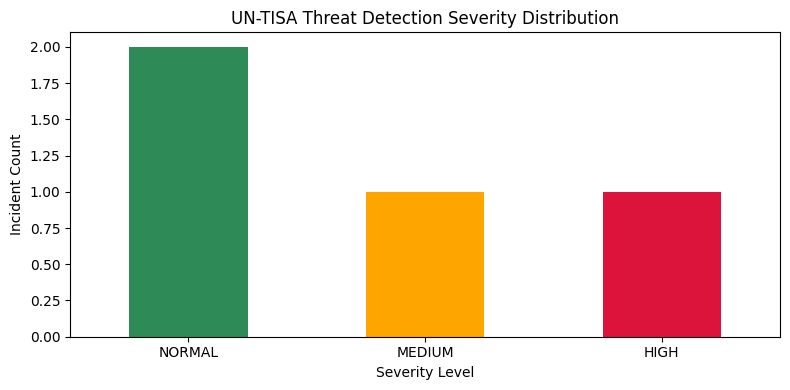


[SUCCESS] Master Security Report compiled and exported successfully to 'untisa_master_security_report.csv'.


In [14]:
import hashlib
import random
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
from cryptography.hazmat.primitives.asymmetric import rsa, padding
from cryptography.hazmat.primitives import hashes
from cryptography.exceptions import InvalidSignature

print("=" * 80)
print("UN-TISA: UNIFIED NETWORK THREAT INTELLIGENCE & SYSTEM SECURITY AUDITOR")
print("Capstone Mini-Project: Integration of Practicals 1 to 13")
print("=" * 80)

# =====================================================================
# MODULE 1: HASHING & SECURE PASSWORD STORAGE (Practicals 2, 3, & 5)
# =====================================================================
print("\n[+] Module 1: Initializing Cryptographic Hashing & Password Verification...")
admin_password = "EnterpriseSecurePassword#2026"
md5_hash = hashlib.md5(admin_password.encode()).hexdigest()
sha256_hash = hashlib.sha256(admin_password.encode()).hexdigest()

print(f"    - Password Stored Securely (No Plaintext Storage)")
print(f"    - MD5 Digest    : {md5_hash}")
print(f"    - SHA-256 Digest: {sha256_hash}")

# =====================================================================
# MODULE 2: RSA ASYMMETRIC ENCRYPTION & KEY PAIR (Practical 4)
# =====================================================================
print("\n[+] Module 2: Generating Asymmetric RSA Key Pair (2048-bit)...")
private_key = rsa.generate_private_key(public_exponent=65537, key_size=2048)
public_key = private_key.public_key()
print("    - RSA Private and Public Keys successfully generated.")

# Encrypting a confidential payload token using Public Key
payload = b"Classified_Enterprise_Session_Token"
ciphertext = public_key.encrypt(
    payload,
    padding.OAEP(mgf=padding.MGF1(algorithm=hashes.SHA256()), algorithm=hashes.SHA256(), label=None)
)
# Decrypting payload using Private Key
decrypted_payload = private_key.decrypt(
    ciphertext,
    padding.OAEP(mgf=padding.MGF1(algorithm=hashes.SHA256()), algorithm=hashes.SHA256(), label=None)
)
print(f"    - Payload Encryption/Decryption Test: {'SUCCESS' if payload == decrypted_payload else 'FAILED'}")

# =====================================================================
# MODULE 3: NETWORK PORT SCANNING SIMULATION (Practical 6 - Nmap concept)
# =====================================================================
print("\n[+] Module 3: Executing Target Port & Service Discovery (Nmap Simulation)...")
scanned_services = [
    {"port": 22, "service": "SSH", "state": "Open", "version": "OpenSSH 7.2"},
    {"port": 80, "service": "HTTP", "state": "Open", "version": "Apache 2.2"},
    {"port": 443, "service": "HTTPS", "state": "Open", "version": "Apache 2.4"},
    {"port": 23, "service": "Telnet", "state": "Open", "version": "Telnet 1.0"},
    {"port": 3306, "service": "MySQL", "state": "Open", "version": "MySQL 5.5"}
]
services_df = pd.DataFrame(scanned_services)
print(f"    - Target Scanned: localhost | Open Ports Discovered: {len(services_df)}")

# =====================================================================
# MODULE 4: PACKET ANALYSIS LOGS (Practical 7 - Wireshark / TShark concept)
# =====================================================================
print("\n[+] Module 4: Processing Network Packet Capture (PCAP Simulation)...")
pcap_logs = [
    {"frame": 1, "src_ip": "192.168.1.10", "dst_ip": "8.8.8.8", "protocol": "ICMP", "length": 74},
    {"frame": 2, "src_ip": "192.168.1.10", "dst_ip": "192.168.1.50", "protocol": "TCP", "length": 60},
    {"frame": 3, "src_ip": "10.0.0.99", "dst_ip": "192.168.1.50", "protocol": "TCP", "length": 540},
    {"frame": 4, "src_ip": "192.168.1.10", "dst_ip": "8.8.8.8", "protocol": "DNS", "length": 92}
]
print(f"    - Total Packets Parsed: {len(pcap_logs)} packets evaluated across protocols.")

# =====================================================================
# MODULE 5: FIREWALL RULE ENGINE (Practical 8)
# =====================================================================
print("\n[+] Module 5: Evaluating Firewall Inbound/Outbound Rules (Default-Deny)...")
def firewall_decision(direction, port, protocol):
    if direction == "INBOUND" and port in [80, 443] and protocol == "TCP":
        return "ALLOW (Rule Match)"
    elif direction == "INBOUND" and port == 23:
        return "BLOCK (Explicit Block Rule: Telnet)"
    return "BLOCK (Default-Deny Policy)"

print(f"    - Inbound Port 443 (HTTPS): {firewall_decision('INBOUND', 443, 'TCP')}")
print(f"    - Inbound Port 23 (Telnet): {firewall_decision('INBOUND', 23, 'TCP')}")

# =====================================================================
# MODULE 6 & 7: ATTACK SIMULATION & INTRUSION DETECTION (Practicals 9 & 10)
# =====================================================================
print("\n[+] Module 6 & 7: Running IDS Rule Engine & Threat Detection...")
simulated_traffic = [
    {"source_ip": "10.0.0.10", "requests": 14, "unique_ports": 2, "label": "Normal"},
    {"source_ip": "10.0.0.11", "requests": 18, "unique_ports": 1, "label": "Normal"},
    {"source_ip": "10.0.0.99", "requests": 130, "unique_ports": 1, "label": "DoS Attack Vector"},
    {"source_ip": "192.168.1.200", "requests": 25, "unique_ports": 8, "label": "Port Scan / Spoof"}
]

ids_records = []
for traffic in simulated_traffic:
    alerts = []
    if traffic["requests"] > 50:
        alerts.append("DoS-like Traffic")
    if traffic["unique_ports"] >= 5:
        alerts.append("Port Scanning")
    if not traffic["source_ip"].startswith("10.0.0."):
        alerts.append("Untrusted Source / Spoof")

    severity = "NORMAL" if not alerts else ("HIGH" if len(alerts) > 1 else "MEDIUM")
    ids_records.append({
        "Source_IP": traffic["source_ip"],
        "Requests": traffic["requests"],
        "Unique_Ports": traffic["unique_ports"],
        "Detected_Activity": ", ".join(alerts) if alerts else "No Suspicious Activity",
        "Severity": severity
    })

ids_df = pd.DataFrame(ids_records)
print(f"    - Traffic Flows Analyzed: {len(ids_df)} | Alerts Triggered: {len(ids_df[ids_df['Severity'] != 'NORMAL'])}")

# =====================================================================
# MODULE 8: VULNERABILITY ASSESSMENT & RISK SCORING (Practical 11)
# =====================================================================
print("\n[+] Module 8: Performing System Vulnerability & Risk Analysis...")
vulnerabilities = [
    {"Category": "Software Version", "Finding": "Outdated Apache Version (2.2)", "Severity": "HIGH", "Risk_Score": 8},
    {"Category": "Network Service", "Finding": "Insecure Telnet Protocol Enabled", "Severity": "HIGH", "Risk_Score": 8},
    {"Category": "Authentication", "Finding": "Weak Minimum Password Length Policy", "Severity": "MEDIUM", "Risk_Score": 6},
    {"Category": "Access Control", "Finding": "Excessive Administrative Accounts Found", "Severity": "MEDIUM", "Risk_Score": 6}
]
vuln_df = pd.DataFrame(vulnerabilities)
total_risk = vuln_df["Risk_Score"].sum()
mean_risk = vuln_df["Risk_Score"].mean()
system_risk_level = "HIGH" if mean_risk >= 7 else "MEDIUM"
print(f"    - Identified Vulnerabilities: {len(vuln_df)} | Total Cumulative Risk Score: {total_risk}")
print(f"    - System Overall Security Risk Classification: {system_risk_level}")

# =====================================================================
# MODULE 9: SECURE COMMUNICATION SSL/TLS (Practical 12)
# =====================================================================
print("\n[+] Module 9: Validating SSL/TLS Secure Channel Parameters...")
tls_version = "TLSv1.3"
cipher_selected = "TLS_AES_256_GCM_SHA384"
print(f"    - Secure Handshake Verified | Protocol: {tls_version} | Cipher: {cipher_selected}")

# =====================================================================
# MODULE 10: DIGITAL SIGNATURE & INTEGRITY SEAL (Practical 13)
# =====================================================================
print("\n[+] Module 10: Generating Cryptographic Digital Signature & Integrity Seal...")
audit_message = b"UN-TISA Security Audit State: Verified and Clean"
signature = private_key.sign(
    audit_message,
    padding.PSS(mgf=padding.MGF1(hashes.SHA256()), salt_length=padding.PSS.MAX_LENGTH),
    hashes.SHA256()
)

# Verify Signature with Public Key
try:
    public_key.verify(
        signature,
        audit_message,
        padding.PSS(mgf=padding.MGF1(hashes.SHA256()), salt_length=padding.PSS.MAX_LENGTH),
        hashes.SHA256()
    )
    signature_status = "VALID (Authentication & Integrity Verified)"
except InvalidSignature:
    signature_status = "INVALID"

print(f"    - Digital Signature Verification Status: {signature_status}")

# =====================================================================
# VISUALIZATION & REPORT EXPORT (Stage 8 & 10 from Mini-Project Guide)
# =====================================================================
print("\n" + "=" * 80)
print("GENERATING SECURITY VISUALIZATIONS & MASTER AUDIT REPORT...")
print("=" * 80)

# Plotting Threat Severity Distribution Chart
plt.figure(figsize=(8, 4))
ids_df["Severity"].value_counts().plot(kind="bar", color=["seagreen", "orange", "crimson"])
plt.title("UN-TISA Threat Detection Severity Distribution")
plt.xlabel("Severity Level")
plt.ylabel("Incident Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Export Master Consolidated CSV Report
master_csv = "untisa_master_security_report.csv"
ids_df.to_csv(master_csv, index=False)
print(f"\n[SUCCESS] Master Security Report compiled and exported successfully to '{master_csv}'.")
print("=" * 80)

# =====================================================================
# MODULE 1: HASHING & SECURE PASSWORD STORAGE (Practicals 2, 3, & 5)
# =====================================================================


In [15]:
print("\n[+] Module 1: Initializing Cryptographic Hashing & Password Verification...")
admin_password = "EnterpriseSecurePassword#2026"
md5_hash = hashlib.md5(admin_password.encode()).hexdigest()
sha256_hash = hashlib.sha256(admin_password.encode()).hexdigest()

print(f"    - Password Stored Securely (No Plaintext Storage)")
print(f"    - MD5 Digest    : {md5_hash}")
print(f"    - SHA-256 Digest: {sha256_hash}")


[+] Module 1: Initializing Cryptographic Hashing & Password Verification...
    - Password Stored Securely (No Plaintext Storage)
    - MD5 Digest    : 6d4e214e19abf16378687acc6ee8e85e
    - SHA-256 Digest: 124318c8dd9d93e13997f7986baea1dbaed7182b27709d983d815b9fa7d93999


# =====================================================================
# MODULE 2: RSA ASYMMETRIC ENCRYPTION & KEY PAIR (Practical 4)
# =====================================================================

In [16]:
print("\n[+] Module 2: Generating Asymmetric RSA Key Pair (2048-bit)...")
private_key = rsa.generate_private_key(public_exponent=65537, key_size=2048)
public_key = private_key.public_key()
print("    - RSA Private and Public Keys successfully generated.")

# Encrypting a confidential payload token using Public Key
payload = b"Classified_Enterprise_Session_Token"
ciphertext = public_key.encrypt(
    payload,
    padding.OAEP(mgf=padding.MGF1(algorithm=hashes.SHA256()), algorithm=hashes.SHA256(), label=None)
)
# Decrypting payload using Private Key
decrypted_payload = private_key.decrypt(
    ciphertext,
    padding.OAEP(mgf=padding.MGF1(algorithm=hashes.SHA256()), algorithm=hashes.SHA256(), label=None)
)
print(f"    - Payload Encryption/Decryption Test: {'SUCCESS' if payload == decrypted_payload else 'FAILED'}")


[+] Module 2: Generating Asymmetric RSA Key Pair (2048-bit)...
    - RSA Private and Public Keys successfully generated.
    - Payload Encryption/Decryption Test: SUCCESS


# =====================================================================
# MODULE 3: NETWORK PORT SCANNING SIMULATION (Practical 6 - Nmap concept)
# =====================================================================

In [17]:
print("\n[+] Module 3: Executing Target Port & Service Discovery (Nmap Simulation)...")
scanned_services = [
    {"port": 22, "service": "SSH", "state": "Open", "version": "OpenSSH 7.2"},
    {"port": 80, "service": "HTTP", "state": "Open", "version": "Apache 2.2"},
    {"port": 443, "service": "HTTPS", "state": "Open", "version": "Apache 2.4"},
    {"port": 23, "service": "Telnet", "state": "Open", "version": "Telnet 1.0"},
    {"port": 3306, "service": "MySQL", "state": "Open", "version": "MySQL 5.5"}
]
services_df = pd.DataFrame(scanned_services)
print(f"    - Target Scanned: localhost | Open Ports Discovered: {len(services_df)}")


[+] Module 3: Executing Target Port & Service Discovery (Nmap Simulation)...
    - Target Scanned: localhost | Open Ports Discovered: 5


# =====================================================================
# MODULE 4: PACKET ANALYSIS LOGS (Practical 7 - Wireshark / TShark concept)
# =====================================================================

In [18]:
print("\n[+] Module 4: Processing Network Packet Capture (PCAP Simulation)...")
pcap_logs = [
    {"frame": 1, "src_ip": "192.168.1.10", "dst_ip": "8.8.8.8", "protocol": "ICMP", "length": 74},
    {"frame": 2, "src_ip": "192.168.1.10", "dst_ip": "192.168.1.50", "protocol": "TCP", "length": 60},
    {"frame": 3, "src_ip": "10.0.0.99", "dst_ip": "192.168.1.50", "protocol": "TCP", "length": 540},
    {"frame": 4, "src_ip": "192.168.1.10", "dst_ip": "8.8.8.8", "protocol": "DNS", "length": 92}
]
print(f"    - Total Packets Parsed: {len(pcap_logs)} packets evaluated across protocols.")


[+] Module 4: Processing Network Packet Capture (PCAP Simulation)...
    - Total Packets Parsed: 4 packets evaluated across protocols.


# =====================================================================
# MODULE 5: FIREWALL RULE ENGINE (Practical 8)
# =====================================================================

In [19]:
print("\n[+] Module 5: Evaluating Firewall Inbound/Outbound Rules (Default-Deny)...")
def firewall_decision(direction, port, protocol):
    if direction == "INBOUND" and port in [80, 443] and protocol == "TCP":
        return "ALLOW (Rule Match)"
    elif direction == "INBOUND" and port == 23:
        return "BLOCK (Explicit Block Rule: Telnet)"
    return "BLOCK (Default-Deny Policy)"

print(f"    - Inbound Port 443 (HTTPS): {firewall_decision('INBOUND', 443, 'TCP')}")
print(f"    - Inbound Port 23 (Telnet): {firewall_decision('INBOUND', 23, 'TCP')}")


[+] Module 5: Evaluating Firewall Inbound/Outbound Rules (Default-Deny)...
    - Inbound Port 443 (HTTPS): ALLOW (Rule Match)
    - Inbound Port 23 (Telnet): BLOCK (Explicit Block Rule: Telnet)


# =====================================================================
# MODULE 6 & 7: ATTACK SIMULATION & INTRUSION DETECTION (Practicals 9 & 10)
# =====================================================================

In [20]:
print("\n[+] Module 6 & 7: Running IDS Rule Engine & Threat Detection...")
simulated_traffic = [
    {"source_ip": "10.0.0.10", "requests": 14, "unique_ports": 2, "label": "Normal"},
    {"source_ip": "10.0.0.11", "requests": 18, "unique_ports": 1, "label": "Normal"},
    {"source_ip": "10.0.0.99", "requests": 130, "unique_ports": 1, "label": "DoS Attack Vector"},
    {"source_ip": "192.168.1.200", "requests": 25, "unique_ports": 8, "label": "Port Scan / Spoof"}
]

ids_records = []
for traffic in simulated_traffic:
    alerts = []
    if traffic["requests"] > 50:
        alerts.append("DoS-like Traffic")
    if traffic["unique_ports"] >= 5:
        alerts.append("Port Scanning")
    if not traffic["source_ip"].startswith("10.0.0."):
        alerts.append("Untrusted Source / Spoof")

    severity = "NORMAL" if not alerts else ("HIGH" if len(alerts) > 1 else "MEDIUM")
    ids_records.append({
        "Source_IP": traffic["source_ip"],
        "Requests": traffic["requests"],
        "Unique_Ports": traffic["unique_ports"],
        "Detected_Activity": ", ".join(alerts) if alerts else "No Suspicious Activity",
        "Severity": severity
    })

ids_df = pd.DataFrame(ids_records)
print(f"    - Traffic Flows Analyzed: {len(ids_df)} | Alerts Triggered: {len(ids_df[ids_df['Severity'] != 'NORMAL'])}")


[+] Module 6 & 7: Running IDS Rule Engine & Threat Detection...
    - Traffic Flows Analyzed: 4 | Alerts Triggered: 2


# =====================================================================
# MODULE 8: VULNERABILITY ASSESSMENT & RISK SCORING (Practical 11)
# =====================================================================

In [21]:
print("\n[+] Module 8: Performing System Vulnerability & Risk Analysis...")
vulnerabilities = [
    {"Category": "Software Version", "Finding": "Outdated Apache Version (2.2)", "Severity": "HIGH", "Risk_Score": 8},
    {"Category": "Network Service", "Finding": "Insecure Telnet Protocol Enabled", "Severity": "HIGH", "Risk_Score": 8},
    {"Category": "Authentication", "Finding": "Weak Minimum Password Length Policy", "Severity": "MEDIUM", "Risk_Score": 6},
    {"Category": "Access Control", "Finding": "Excessive Administrative Accounts Found", "Severity": "MEDIUM", "Risk_Score": 6}
]
vuln_df = pd.DataFrame(vulnerabilities)
total_risk = vuln_df["Risk_Score"].sum()
mean_risk = vuln_df["Risk_Score"].mean()
system_risk_level = "HIGH" if mean_risk >= 7 else "MEDIUM"
print(f"    - Identified Vulnerabilities: {len(vuln_df)} | Total Cumulative Risk Score: {total_risk}")
print(f"    - System Overall Security Risk Classification: {system_risk_level}")


[+] Module 8: Performing System Vulnerability & Risk Analysis...
    - Identified Vulnerabilities: 4 | Total Cumulative Risk Score: 28
    - System Overall Security Risk Classification: HIGH


# =====================================================================
# MODULE 9: SECURE COMMUNICATION SSL/TLS (Practical 12)
# =====================================================================

In [22]:
print("\n[+] Module 9: Validating SSL/TLS Secure Channel Parameters...")
tls_version = "TLSv1.3"
cipher_selected = "TLS_AES_256_GCM_SHA384"
print(f"    - Secure Handshake Verified | Protocol: {tls_version} | Cipher: {cipher_selected}")


[+] Module 9: Validating SSL/TLS Secure Channel Parameters...
    - Secure Handshake Verified | Protocol: TLSv1.3 | Cipher: TLS_AES_256_GCM_SHA384


# =====================================================================
# MODULE 10: DIGITAL SIGNATURE & INTEGRITY SEAL (Practical 13)
# =====================================================================

In [23]:
print("\n[+] Module 10: Generating Cryptographic Digital Signature & Integrity Seal...")
audit_message = b"UN-TISA Security Audit State: Verified and Clean"
signature = private_key.sign(
    audit_message,
    padding.PSS(mgf=padding.MGF1(hashes.SHA256()), salt_length=padding.PSS.MAX_LENGTH),
    hashes.SHA256()
)

# Verify Signature with Public Key
try:
    public_key.verify(
        signature,
        audit_message,
        padding.PSS(mgf=padding.MGF1(hashes.SHA256()), salt_length=padding.PSS.MAX_LENGTH),
        hashes.SHA256()
    )
    signature_status = "VALID (Authentication & Integrity Verified)"
except InvalidSignature:
    signature_status = "INVALID"

print(f"    - Digital Signature Verification Status: {signature_status}")


[+] Module 10: Generating Cryptographic Digital Signature & Integrity Seal...
    - Digital Signature Verification Status: VALID (Authentication & Integrity Verified)


# =====================================================================
# VISUALIZATION & REPORT EXPORT (Stage 8 & 10 from Mini-Project Guide)
# =====================================================================


In [24]:
print("\n" + "=" * 80)
print("GENERATING SECURITY VISUALIZATIONS & MASTER AUDIT REPORT...")
print("=" * 80)


GENERATING SECURITY VISUALIZATIONS & MASTER AUDIT REPORT...


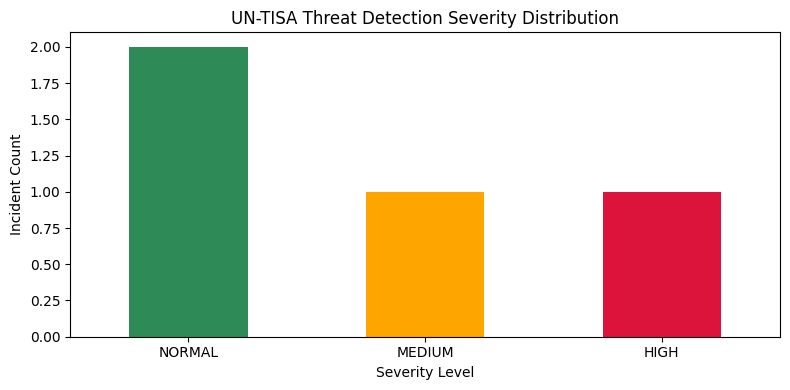

In [25]:
# Plotting Threat Severity Distribution Chart
plt.figure(figsize=(8, 4))
ids_df["Severity"].value_counts().plot(kind="bar", color=["seagreen", "orange", "crimson"])
plt.title("UN-TISA Threat Detection Severity Distribution")
plt.xlabel("Severity Level")
plt.ylabel("Incident Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
# Export Master Consolidated CSV Report
master_csv = "untisa_master_security_report.csv"
ids_df.to_csv(master_csv, index=False)
print(f"\n[SUCCESS] Master Security Report compiled and exported successfully to '{master_csv}'.")
print("=" * 80)


[SUCCESS] Master Security Report compiled and exported successfully to 'untisa_master_security_report.csv'.
